In [ ]:
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
def plot_wave(y, sr, duration=None, title="Waveform", xlabel="Time (s)", ylabel="Amplitude"):
    """
    Plot a waveform `y` sampled at `sr` Hz.
    Optionally, limit x-axis to `duration` seconds.
    """
    t = np.arange(len(y)) / sr
    plt.figure(figsize=(8, 2))
    plt.plot(t, y)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    if duration is not None:
        plt.xlim(0, duration)
    plt.grid(True)
    plt.show()

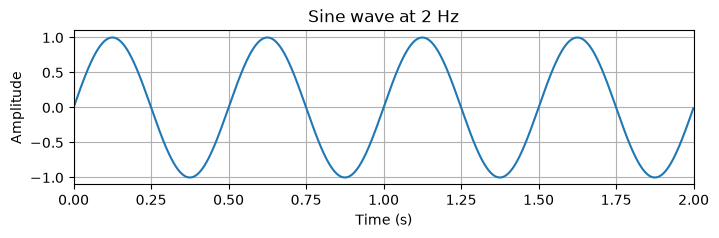

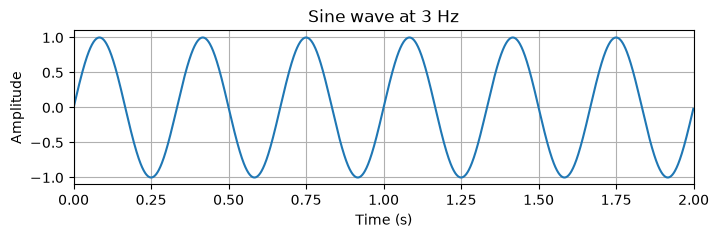

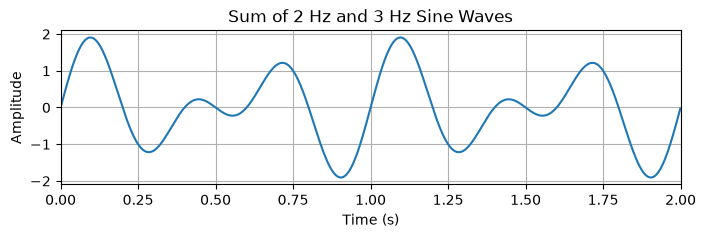

In [ ]:
# Plot a 2 Hz sine wave, a 3 Hz sine wave, and their sum

duration = 2  # seconds
freq1 = 2  # Hz
freq2 = 3  # Hz
sr = 1000  # samples per second

t = np.linspace(0, duration, int(sr * duration), endpoint=False)
y1 = np.sin(2 * np.pi * freq1 * t)
y2 = np.sin(2 * np.pi * freq2 * t)
y_sum = y1 + y2

plot_wave(y1, sr, duration=duration, title="Sine wave at 2 Hz")
plot_wave(y2, sr, duration=duration, title="Sine wave at 3 Hz")
plot_wave(y_sum, sr, duration=duration, title="Sum of 2 Hz and 3 Hz Sine Waves")

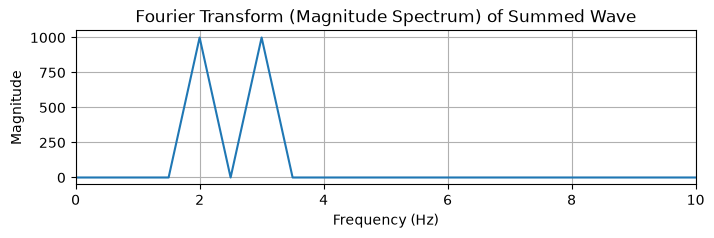

In [ ]:
# Apply Fourier Transform to the summed wave
Y_sum_fft = np.fft.fft(y_sum)

freqs = np.fft.fftfreq(len(y_sum), 1 / sr)

# Only take the positive part of the spectrum for plotting
half = len(y_sum) // 2

# Limit the x-axis to a smaller frequency range (e.g., 0-10 Hz) to make spikes more visible
max_freq_display = 10
idx = np.where((freqs[:half] >= 0) & (freqs[:half] <= max_freq_display))

plt.figure(figsize=(8, 2))
plt.plot(freqs[:half][idx], np.abs(Y_sum_fft)[:half][idx])
plt.title("Fourier Transform (Magnitude Spectrum) of Summed Wave")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, max_freq_display)
plt.grid(True)
plt.show()

## How does `fft` find those spikes?

`np.fft.fft` found the 2 Hz and 3 Hz waves hiding in `y_sum`. Let's rebuild it from scratch, one small idea at a time, checking against numpy as we go.

Start with a simpler question: *how much 2 Hz is in `y_sum`?* One way to find out is to multiply the signal by a 2 Hz "probe" wave and add up the result. Where the two waves move together the product is positive; where they disagree it's negative.

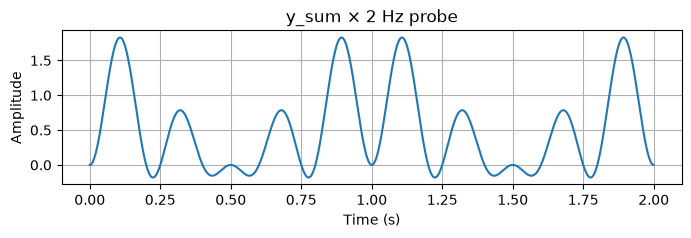

np.float64(1000.0)

In [ ]:
probe = np.sin(2 * np.pi * 2 * t)
plot_wave(y_sum * probe, sr, title="y_sum × 2 Hz probe")
(y_sum * probe).sum()

The product is mostly above zero, so the sum is big. Now try a frequency that isn't in there:

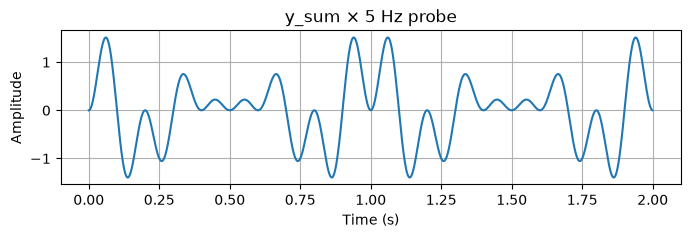

np.float64(6.394884621840902e-14)

In [ ]:
probe = np.sin(2 * np.pi * 5 * t)
plot_wave(y_sum * probe, sr, title="y_sum × 5 Hz probe")
(y_sum * probe).sum()

The positive and negative parts cancel, so the sum is (almost exactly) zero. Let's score every whole frequency from 0 to 10 Hz:

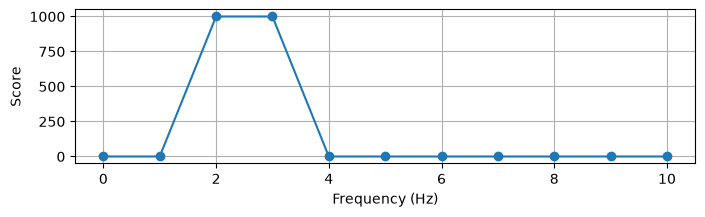

In [ ]:
def score(y, f):
    "How much `y` lines up with a sine wave at `f` Hz."
    return (y * np.sin(2 * np.pi * f * t)).sum()


fs = np.arange(11)
plt.figure(figsize=(8, 2))
plt.plot(fs, [score(y_sum, f) for f in fs], "o-")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Score")
plt.grid(True)
plt.show()

That's already a spectrum, built from nothing but multiply and add. (Why exactly 1000? Where the probe matches, each product is $\sin^2$, which averages $\tfrac12$ over whole cycles, and there are 2000 samples.)

## Problem: phase

Our probe is a sine. What if the signal is a cosine at the same frequency, which is the same wave shifted by a quarter of a cycle?

In [ ]:
y_cos = np.cos(2 * np.pi * 2 * t)
score(y_cos, 2)

np.float64(-7.105427357601002e-15)

Zero! A cosine agrees with a sine for half of each cycle and disagrees for the other half, so the sine probe misses it completely.

The fix is to probe with a cosine *and* a sine. Any shifted wave is some mix of the two, and Pythagoras combines the two scores into one that doesn't care about the shift:

In [ ]:
def score(y, f):
    "How much `y` contains frequency `f`, whatever its phase."
    c = (y * np.cos(2 * np.pi * f * t)).sum()
    s = (y * np.sin(2 * np.pi * f * t)).sum()
    return np.sqrt(c**2 + s**2)


[score(np.sin(2 * np.pi * 2 * t + phase), 2).round() for phase in np.linspace(0, 2 * np.pi, 8)]

[np.float64(1000.0),
 np.float64(1000.0),
 np.float64(1000.0),
 np.float64(1000.0),
 np.float64(1000.0),
 np.float64(1000.0),
 np.float64(1000.0),
 np.float64(1000.0)]

## Complex numbers do the bookkeeping

Carrying two sums around is clumsy. Euler's formula packs a cosine and a sine into one complex number:

$$e^{-i\theta} = \cos\theta - i\sin\theta$$

So multiplying by $e^{-2\pi i f t}$ and summing computes the cosine score as the real part and minus the sine score as the imaginary part, in one go. `np.abs` then does the Pythagoras.

In [ ]:
def dft_at(y, f):
    "The Fourier transform of `y` at `f` Hz: cosine score - i × sine score."
    return (y * np.exp(-2j * np.pi * f * t)).sum()


dft_at(y_sum, 2), np.abs(dft_at(y_sum, 2))

(np.complex128(-8.526512829121202e-14-1000j), np.float64(1000.0))

Compare numpy's answer at 2 Hz:

In [ ]:
Y_sum_fft[freqs == 2]

array([-3.04645847e-13-1000.j])

Same number. It's $-1000i$: a cosine score of 0 and a sine score of 1000, because `y_sum` is built from sines.

## Which frequencies to check?

We picked 0–10 Hz by hand. `fft` checks the frequencies that fit a whole number of cycles into the signal. With $N$ samples at `sr` Hz, that's $k$ cycles for $k = 0, 1, \dots, N-1$, so $f_k = k \cdot \text{sr} / N$. Here that's steps of 0.5 Hz, which is what `fftfreq` returned.

Substituting $t = n / \text{sr}$ makes `sr` cancel out, leaving only sample numbers:

$$X_k = \sum_{n=0}^{N-1} x_n \, e^{-2\pi i k n / N}$$

That's the discrete Fourier transform (DFT). In code:

In [ ]:
def dft(x):
    "Discrete Fourier transform: probe `x` at every frequency that fits a whole number of cycles."
    N = len(x)
    n = np.arange(N)
    return np.array([(x * np.exp(-2j * np.pi * k * n / N)).sum() for k in range(N)])


np.allclose(dft(y_sum), Y_sum_fft)

True

We've rebuilt `np.fft.fft`.

That also explains "only take the positive part" above. Past $k = N/2$ the probe turns so far between samples that it looks the same as turning backwards, so those bins are *negative* frequencies (see `freqs[half]`). For a real signal they're mirror images (complex conjugates) of the positive ones and add nothing new:

In [ ]:
X = dft(y_sum)
freqs[half], np.allclose(X[1:half], X[:half:-1].conj())

(np.float64(-500.0), True)

## It's a matrix multiply

Each probe is a row of numbers. Stack all $N$ of them and the DFT is one matrix times the signal. Here's the real part of that matrix for a tiny $N = 32$: row $k$ is a cosine with $k$ cycles.

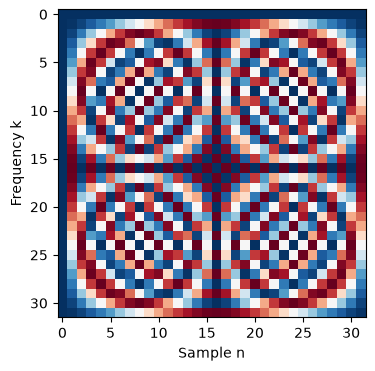

In [ ]:
def dft_matrix(N):
    "Row k holds the probe for k cycles per signal."
    n = np.arange(N)
    return np.exp(-2j * np.pi * np.outer(n, n) / N)


plt.figure(figsize=(4, 4))
plt.imshow(dft_matrix(32).real, cmap="RdBu")
plt.xlabel("Sample n")
plt.ylabel("Frequency k")
plt.show()

In [ ]:
W = dft_matrix(len(y_sum))
np.allclose(W @ y_sum, Y_sum_fft)

True

Tidy, but $N$ probes of $N$ samples each is $N^2$ multiplications: 4 million here, and about $7 \times 10^{12}$ for a minute of CD audio. Even skipping the time it took to build `W`, numpy is much faster:

In [ ]:
%timeit W @ y_sum
%timeit np.fft.fft(y_sum)

803 μs ± 40 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
13.6 μs ± 311 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


## The fast part

The FFT gets the same answer with far less work by noticing that the DFT repeats itself. Split the sum into even samples $n = 2m$ and odd samples $n = 2m+1$:

$$X_k = \sum_{m} x_{2m}\, e^{-2\pi i k m / (N/2)} \;+\; e^{-2\pi i k / N} \sum_{m} x_{2m+1}\, e^{-2\pi i k m / (N/2)} = E_k + w_k O_k$$

$E$ and $O$ are just DFTs of the half-length signals `x[0::2]` and `x[1::2]`, and $w_k = e^{-2\pi i k/N}$ is called a *twiddle factor*. Let's check that before going further:

In [ ]:
N = len(y_sum)
E, O = dft(y_sum[0::2]), dft(y_sum[1::2])
w = np.exp(-2j * np.pi * np.arange(N // 2) / N)
np.allclose(E + w * O, Y_sum_fft[: N // 2])

True

Two DFTs of half the size cost $2 \times (N/2)^2 = N^2/2$, so that's already twice as fast.

But $E$ and $O$ only have $N/2$ values. What about $X_k$ for $k \ge N/2$? A half-length DFT repeats every $N/2$ bins, so $E$ and $O$ can be reused as they are. Meanwhile the twiddle flips sign, $w_{k+N/2} = -w_k$, because it's half a turn further round:

$$X_{k+N/2} = E_k - w_k O_k$$

In [ ]:
np.allclose(E - w * O, Y_sum_fft[N // 2 :])

True

So one DFT of size $N$ is two DFTs of size $N/2$ plus $N$ cheap multiply-adds. Each half can be split the same way, and so on, until the pieces can't be halved any more. That recursion is the FFT (the Cooley–Tukey algorithm, 1965).

Our $N = 2000$ halves four times, down to 125. That's odd, so we finish those pieces off with plain `dft`:

In [ ]:
def fft(x):
    "Fast Fourier transform: split into even and odd samples until the length is odd."
    N = len(x)
    if N % 2:
        return dft(x)
    E, O = fft(x[0::2]), fft(x[1::2])
    wO = np.exp(-2j * np.pi * np.arange(N // 2) / N) * O
    return np.concatenate([E + wO, E - wO])


np.allclose(fft(y_sum), Y_sum_fft)

True

In [ ]:
%timeit dft(y_sum)
%timeit fft(y_sum)
%timeit np.fft.fft(y_sum)

54.3 ms ± 90 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)
7.51 ms ± 187 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
13.6 μs ± 53.9 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


When $N$ is a power of 2 the halving goes all the way down to single samples: $\log_2 N$ levels with $N$ work each, so $N \log_2 N$ instead of $N^2$. The gap grows quickly:

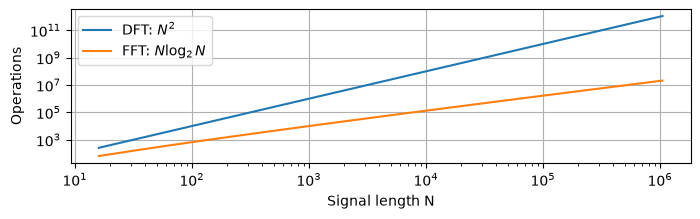

In [ ]:
Ns = 2 ** np.arange(4, 21)
plt.figure(figsize=(8, 2))
plt.loglog(Ns, Ns**2, label="DFT: $N^2$")
plt.loglog(Ns, Ns * np.log2(Ns), label=r"FFT: $N \log_2 N$")
plt.xlabel("Signal length N")
plt.ylabel("Operations")
plt.legend()
plt.grid(True)
plt.show()

`np.fft.fft` uses the same idea, written in C, with extra tricks: it splits by other factors too (3, 5, ...), and `np.fft.rfft` skips the mirrored negative half for real signals.

One loose end: why were the spikes 1000 tall when the waves have amplitude 1? A wave of amplitude $A$ scores $A \cdot N/2$, so dividing by $N/2$ turns the magnitudes back into amplitudes:

In [ ]:
(np.abs(Y_sum_fft) / (len(y_sum) / 2))[(freqs == 2) | (freqs == 3)]

array([1., 1.])